In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"🔥 TensorFlow versión: {tf.__version__}")
print(f"🧠 Keras versión:      {keras.__version__}")

# 1. Cargar los conjuntos del Modelo 4 (Notebook 08)
processed_dir = "../data/processed/modelo4"
df_train = pd.read_parquet(os.path.join(processed_dir, "train.parquet"))
df_val   = pd.read_parquet(os.path.join(processed_dir, "val.parquet"))
df_test  = pd.read_parquet(os.path.join(processed_dir, "test.parquet"))

y_train = df_train['accion'].values
y_val   = df_val['accion'].values
y_test  = df_test['accion'].values

print("\n📖 Conjuntos del Modelo 4 cargados (partición por sesión de juego):")
print(f" • Entrenamiento (Train): {len(df_train):,} decisiones de {df_train['sesion'].nunique()} sesiones")
print(f" • Validación    (Val):   {len(df_val):,} decisiones de {df_val['sesion'].nunique()} sesiones")
print(f" • Prueba        (Test):  {len(df_test):,} decisiones de {df_test['sesion'].nunique()} sesiones")

os.makedirs('../informe/figuras', exist_ok=True)
os.makedirs('../informe/metricas', exist_ok=True)
resultados = {}

🔥 TensorFlow versión: 2.21.0
🧠 Keras versión:      3.15.1

📖 Conjuntos del Modelo 4 cargados (partición por sesión de juego):
 • Entrenamiento (Train): 61,641 decisiones de 64 sesiones
 • Validación    (Val):   13,116 decisiones de 14 sesiones
 • Prueba        (Test):  16,599 decisiones de 14 sesiones


In [2]:
# Grupos de variables del Modelo 4
G0_ORIGINALES = ['calle', 'bote', 'to_call', 'stack', 'pot_odds']
PUBLICAS = ['calle', 'bote_bb', 'to_call_bb', 'stack_bb', 'pot_odds',
            'n_activos', 'n_allin', 'detras', 'pos_pre', 'pos_post', 'es_sb', 'es_bb', 'es_boton',
            'eff_bb', 'spr', 'call_vs_bote', 'call_es_allin', 'invertido_bb',
            'subidas_calle', 'callers_calle', 'checks_calle', 'subidas_pre', 'ult_apuesta_vs_bote',
            'ya_actuo_calle', 'ya_subio_calle', 'es_agresor_pre', 'es_agresor_prev', 'hay_agresor_prev',
            'b_n', 'b_pareada', 'b_trio', 'b_max_palo', 'b_alta', 'b_broadway', 'b_conect',
            'es_pluribus']                                     # ¿decide la IA o un profesional?
CARTAS = ['c_alta', 'c_baja', 'c_pareja', 'c_suited', 'c_gap',   # cartas privadas del que decide
          'c_fuerza', 'c_clase', 'c_proy_color', 'c_proy_escalera']
EQUITY = ['c_eq_pre', 'c_equity']                           # salida del motor matemático (treys + Monte Carlo)
FEATURES = PUBLICAS + CARTAS + EQUITY

print(f" • Variables públicas de la mesa:       {len(PUBLICAS)}")
print(f" • Variables de cartas privadas:        {len(CARTAS)}")
print(f" • Equity del motor matemático:         {len(EQUITY)}")
print(f"🎯 Modelo 4 final: {len(FEATURES)} variables")

 • Variables públicas de la mesa:       36
 • Variables de cartas privadas:        9
 • Equity del motor matemático:         2
🎯 Modelo 4 final: 47 variables


In [3]:
from sklearn.preprocessing import StandardScaler

VARIABLES_LOG = ['bote', 'to_call', 'stack', 'bote_bb', 'to_call_bb', 'stack_bb', 'eff_bb', 'spr',
                 'invertido_bb', 'ult_apuesta_vs_bote']

def preparar(df, cols):
    """Selecciona columnas, aplica log a las cantidades de dinero y devuelve float32."""
    X = df[cols].copy()
    for c in VARIABLES_LOG:
        if c in X.columns:
            X[c] = np.log1p(X[c].clip(lower=0))
    return X.values.astype('float32')

# REGLA METODOLÓGICA: el escalador se ajusta SOLO con Train
scaler = StandardScaler().fit(preparar(df_train, FEATURES))
X_train = scaler.transform(preparar(df_train, FEATURES))
X_val   = scaler.transform(preparar(df_val, FEATURES))
X_test  = scaler.transform(preparar(df_test, FEATURES))

print("=" * 65)
print("  ESCALADO DE VARIABLES COMPLETADO (Doc. Maestro § 8.2)")
print("=" * 65)
print(f" • Dimensión de X_train: {X_train.shape}")
print(f" • Dimensión de X_val:   {X_val.shape}")
print(f" • Dimensión de X_test:  {X_test.shape}")

  ESCALADO DE VARIABLES COMPLETADO (Doc. Maestro § 8.2)
 • Dimensión de X_train: (61641, 47)
 • Dimensión de X_val:   (13116, 47)
 • Dimensión de X_test:  (16599, 47)


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

es_humano = df_test['es_pluribus'].values == 0

def evaluar(nombre, probabilidades):
    """Métricas oficiales sobre Test, en total y separadas para profesionales y para Pluribus."""
    pred = probabilidades.argmax(axis=1)
    fila = {
        'accuracy': round(float(accuracy_score(y_test, pred)), 4),
        'acc_profesionales': round(float(accuracy_score(y_test[es_humano], pred[es_humano])), 4),
        'acc_pluribus': round(float(accuracy_score(y_test[~es_humano], pred[~es_humano])), 4),
        'f1_macro': round(float(f1_score(y_test, pred, average='macro')), 4),
        'log_loss': round(float(log_loss(y_test, np.clip(probabilidades, 1e-7, 1), labels=[0, 1, 2])), 4),
    }
    resultados[nombre] = fila
    print(f" • {nombre:<44} Acc={fila['accuracy'] * 100:.2f}% (pros {fila['acc_profesionales'] * 100:.1f}% | "
          f"Pluribus {fila['acc_pluribus'] * 100:.1f}%)  F1-Macro={fila['f1_macro']:.3f}  LogLoss={fila['log_loss']:.3f}")
    return pred

print("📏 BASELINES DEL MODELO 4 (mismos datos y misma partición):\n")
dummy = DummyClassifier(strategy='most_frequent').fit(df_train[G0_ORIGINALES], y_train)
evaluar('Baseline 1: Clase Mayoritaria (Fold)', dummy.predict_proba(df_test[G0_ORIGINALES]))
arbol = DecisionTreeClassifier(max_depth=3, random_state=42).fit(df_train[G0_ORIGINALES], y_train)
evaluar('Baseline 2: Árbol Prof. 3 (5 variables)', arbol.predict_proba(df_test[G0_ORIGINALES]))
gbm = HistGradientBoostingClassifier(max_iter=800, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0,
                                     early_stopping=True, validation_fraction=0.15, random_state=0)
gbm.fit(df_train[FEATURES], y_train)
_ = evaluar('Referencia: Gradient Boosting (47 variables)', gbm.predict_proba(df_test[FEATURES]))

📏 BASELINES DEL MODELO 4 (mismos datos y misma partición):

 • Baseline 1: Clase Mayoritaria (Fold)         Acc=53.80% (pros 54.0% | Pluribus 52.9%)  F1-Macro=0.233  LogLoss=7.446
 • Baseline 2: Árbol Prof. 3 (5 variables)      Acc=69.25% (pros 69.7% | Pluribus 67.2%)  F1-Macro=0.485  LogLoss=0.679


C:\Users\lucas\miniconda3\envs\ia_local\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
C:\Users\lucas\miniconda3\envs\ia_local\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


 • Referencia: Gradient Boosting (47 variables) Acc=87.20% (pros 87.5% | Pluribus 85.7%)  F1-Macro=0.836  LogLoss=0.285


In [5]:
def crear_red(n_entradas, nombre="PHT_T_Modelo4"):
    """MLP piramidal (256 ➔ 128 ➔ 64 ➔ 3) con más Dropout: el dataset es 40 veces más pequeño que el del Modelo 3."""
    modelo = keras.Sequential([
        layers.Input(shape=(n_entradas,), name="Entrada_Variables"),
        layers.Dense(256, activation='relu', name="Capa_Densa_256"),
        layers.BatchNormalization(name="Normalizacion_1"),
        layers.Dropout(0.3, name="Dropout_30pct_1"),
        layers.Dense(128, activation='relu', name="Capa_Densa_128"),
        layers.BatchNormalization(name="Normalizacion_2"),
        layers.Dropout(0.3, name="Dropout_30pct_2"),
        layers.Dense(64, activation='relu', name="Capa_Densa_64"),
        layers.Dropout(0.2, name="Dropout_20pct_3"),
        layers.Dense(3, activation='softmax', name="Salida_Probabilidades")
    ], name=nombre)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

def guardianes():
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)]

tf.random.set_seed(42)
modelo = crear_red(X_train.shape[1])
print("=" * 65)
print("  ARQUITECTURA DE LA RED NEURONAL — MODELO 4")
print("=" * 65)
modelo.summary()

  ARQUITECTURA DE LA RED NEURONAL — MODELO 4


Model: "PHT_T_Modelo4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Capa_Densa_256 (Dense)          │ (None, 256)            │        12,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Normalizacion_1                 │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_30pct_1 (Dropout)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Densa_128 (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Normalizacion_2                 │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_30pct_2 (Dropout)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Densa_64 (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_20pct_3 (Dropout)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida_Probabilidades (Dense)   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,171 (215.51 KB)

 Trainable params: 54,403 (212.51 KB)

 Non-trainable params: 768 (3.00 KB)

In [6]:
print("🚀 INICIANDO EL ENTRENAMIENTO DEL MODELO 4...")
print(f" • Datos de Entrenamiento: {len(X_train):,} decisiones")
print(f" • Datos de Validación:    {len(X_val):,} decisiones")
print(" • Tamaño del lote (Batch): 256 | Épocas máximas: 100 (parada automática)\n")
t0 = time.time()
history = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=100, batch_size=256, callbacks=guardianes(), verbose=2)
print(f"\n✅ ¡ENTRENAMIENTO COMPLETADO en {time.time() - t0:.0f} s ({len(history.history['loss'])} épocas)!")

🚀 INICIANDO EL ENTRENAMIENTO DEL MODELO 4...
 • Datos de Entrenamiento: 61,641 decisiones
 • Datos de Validación:    13,116 decisiones
 • Tamaño del lote (Batch): 256 | Épocas máximas: 100 (parada automática)

Epoch 1/100


241/241 - 5s - 21ms/step - accuracy: 0.7885 - loss: 0.4874 - val_accuracy: 0.8432 - val_loss: 0.3644 - learning_rate: 0.0010


Epoch 2/100


241/241 - 2s - 7ms/step - accuracy: 0.8250 - loss: 0.3856 - val_accuracy: 0.8525 - val_loss: 0.3299 - learning_rate: 0.0010


Epoch 3/100


241/241 - 3s - 13ms/step - accuracy: 0.8367 - loss: 0.3607 - val_accuracy: 0.8609 - val_loss: 0.3184 - learning_rate: 0.0010


... (109 outputs left out)

241/241 - 2s - 7ms/step - accuracy: 0.8773 - loss: 0.2764 - val_accuracy: 0.8783 - val_loss: 0.2767 - learning_rate: 1.0000e-05


Epoch 59/100


241/241 - 2s - 6ms/step - accuracy: 0.8772 - loss: 0.2766 - val_accuracy: 0.8782 - val_loss: 0.2767 - learning_rate: 1.0000e-05



✅ ¡ENTRENAMIENTO COMPLETADO en 110 s (59 épocas)!


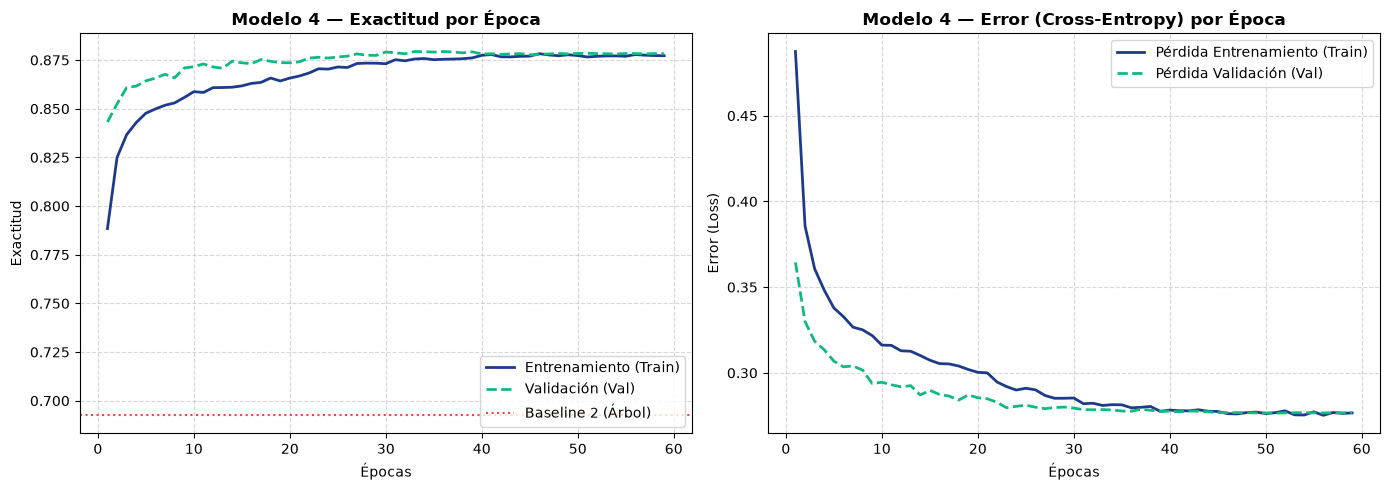

🎯 Mejor exactitud en Validación: 87.94%
📉 Menor pérdida en Validación:   0.2765
📏 Brecha Train - Val (última época): -0.10 puntos


In [7]:
acc, val_acc = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'], history.history['val_loss']
epocas = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epocas, acc, label='Entrenamiento (Train)', color='#1e3a8a', linewidth=2)
plt.plot(epocas, val_acc, label='Validación (Val)', color='#10b981', linewidth=2, linestyle='--')
plt.axhline(y=resultados['Baseline 2: Árbol Prof. 3 (5 variables)']['accuracy'], color='#ef4444', linestyle=':', label='Baseline 2 (Árbol)')
plt.title('Modelo 4 — Exactitud por Época', fontsize=12, fontweight='bold')
plt.xlabel('Épocas'); plt.ylabel('Exactitud'); plt.legend(loc='lower right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.subplot(1, 2, 2)
plt.plot(epocas, loss, label='Pérdida Entrenamiento (Train)', color='#1e3a8a', linewidth=2)
plt.plot(epocas, val_loss, label='Pérdida Validación (Val)', color='#10b981', linewidth=2, linestyle='--')
plt.title('Modelo 4 — Error (Cross-Entropy) por Época', fontsize=12, fontweight='bold')
plt.xlabel('Épocas'); plt.ylabel('Error (Loss)'); plt.legend(loc='upper right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('../informe/figuras/modelo4_curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 65)
print(f"🎯 Mejor exactitud en Validación: {max(val_acc) * 100:.2f}%")
print(f"📉 Menor pérdida en Validación:   {min(val_loss):.4f}")
print(f"📏 Brecha Train - Val (última época): {(acc[-1] - val_acc[-1]) * 100:.2f} puntos")
print("=" * 65)

🎓 APLICANDO EL EXAMEN FINAL EN TEST (16,599 decisiones de sesiones nunca vistas)...



 • 🎯 Red Neuronal MLP — Modelo 4 (cartas + contexto) Acc=87.39% (pros 87.7% | Pluribus 86.1%)  F1-Macro=0.839  LogLoss=0.279

📋 REPORTE DE CLASIFICACIÓN DETALLADO:
                precision    recall  f1-score   support

      Fold (0)     0.9497    0.9515    0.9506      8931
Check/Call (1)     0.7942    0.7931    0.7937      4287
 Bet/Raise (2)     0.7739    0.7714    0.7726      3381

      accuracy                         0.8739     16599
     macro avg     0.8393    0.8387    0.8390     16599
  weighted avg     0.8737    0.8739    0.8738     16599

🃏 EXACTITUD POR CALLE (con intervalo de confianza del 95%):
 • Preflop : 91.55% ± 0.51 (11,399 decisiones)
 • Flop    : 80.00% ± 1.57 (2,495 decisiones)
 • Turn    : 76.69% ± 2.07 (1,600 decisiones)
 • River   : 76.65% ± 2.49 (1,105 decisiones)


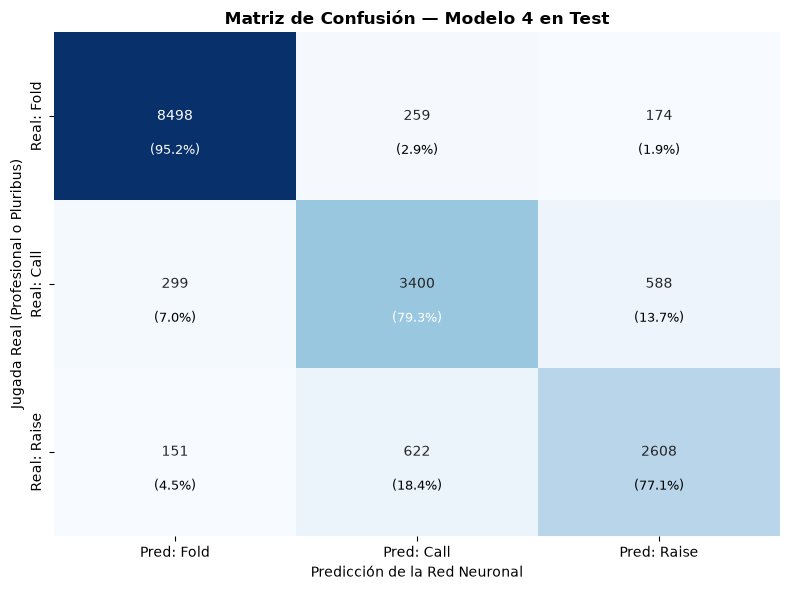

In [8]:
from sklearn.metrics import classification_report, confusion_matrix

print(f"🎓 APLICANDO EL EXAMEN FINAL EN TEST ({len(y_test):,} decisiones de sesiones nunca vistas)...\n")
prob_test = modelo.predict(X_test, verbose=0)
y_pred = evaluar('🎯 Red Neuronal MLP — Modelo 4 (cartas + contexto)', prob_test)

nombres_clases = ['Fold (0)', 'Check/Call (1)', 'Bet/Raise (2)']
print("\n📋 REPORTE DE CLASIFICACIÓN DETALLADO:")
print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=4))
reporte_clases_m4 = classification_report(y_test, y_pred, target_names=nombres_clases, output_dict=True)

# Exactitud por calle con intervalo de confianza del 95% (aproximación normal)
nombres_calles = {0: 'Preflop', 1: 'Flop', 2: 'Turn', 3: 'River'}
print("🃏 EXACTITUD POR CALLE (con intervalo de confianza del 95%):")
por_calle = []
for calle, nombre in nombres_calles.items():
    m = df_test['calle'].values == calle
    p = accuracy_score(y_test[m], y_pred[m])
    margen = 1.96 * np.sqrt(p * (1 - p) / m.sum())
    por_calle.append({'calle': nombre, 'decisiones': int(m.sum()), 'accuracy': round(float(p), 4), 'margen_95': round(float(margen), 4)})
    print(f" • {nombre:<8}: {p * 100:.2f}% ± {margen * 100:.2f} ({m.sum():,} decisiones)")

cm = confusion_matrix(y_test, y_pred)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred: Fold', 'Pred: Call', 'Pred: Raise'],
            yticklabels=['Real: Fold', 'Real: Call', 'Real: Raise'])
for i in range(3):
    for j in range(3):
        color_texto = 'white' if cm[i, j] > (len(y_test) / 6) else 'black'
        plt.text(j + 0.5, i + 0.7, f"({cm_pct[i, j]:.1f}%)", ha="center", va="center", color=color_texto, fontsize=9)
plt.title('Matriz de Confusión — Modelo 4 en Test', fontsize=12, fontweight='bold')
plt.ylabel('Jugada Real (Profesional o Pluribus)'); plt.xlabel('Predicción de la Red Neuronal')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo4_matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# EXPERIMENTO 1 — ABLACIÓN: ¿cuánto aportan las cartas y cuánto la equity del motor?
print("🧪 ABLACIÓN: misma red, con y sin cartas privadas\n")
for nombre, cols in [('Sin cartas (solo contexto público)', PUBLICAS),
                     ('Cartas sin equity del motor', PUBLICAS + CARTAS),
                     ('Completo (cartas + equity del motor)', FEATURES)]:
    if cols is FEATURES:
        prob = prob_test
    else:
        esc = StandardScaler().fit(preparar(df_train, cols))
        tf.random.set_seed(42)
        red = crear_red(len(cols), nombre="Ablacion")
        red.fit(esc.transform(preparar(df_train, cols)), y_train,
                validation_data=(esc.transform(preparar(df_val, cols)), y_val),
                epochs=100, batch_size=256, callbacks=guardianes(), verbose=0)
        prob = red.predict(esc.transform(preparar(df_test, cols)), verbose=0)
    evaluar(f"Ablación: {nombre}", prob)

🧪 ABLACIÓN: misma red, con y sin cartas privadas



 • Ablación: Sin cartas (solo contexto público) Acc=70.78% (pros 71.3% | Pluribus 68.1%)  F1-Macro=0.583  LogLoss=0.619


 • Ablación: Cartas sin equity del motor        Acc=87.19% (pros 87.5% | Pluribus 85.7%)  F1-Macro=0.837  LogLoss=0.285
 • Ablación: Completo (cartas + equity del motor) Acc=87.39% (pros 87.7% | Pluribus 86.1%)  F1-Macro=0.839  LogLoss=0.279


In [10]:
from sklearn.model_selection import GroupKFold

# EXPERIMENTO 2 — VALIDACIÓN CRUZADA POR SESIONES: ¿qué tan estables son las métricas?
# Se usan las 10.000 manos: 5 rondas, cada una evalúa con sesiones que la red no vio
df_todo = pd.concat([df_train, df_val, df_test], ignore_index=True)
X_todo_crudo = preparar(df_todo, FEATURES)
y_todo = df_todo['accion'].values
grupos = df_todo['sesion'].values

print("🔁 VALIDACIÓN CRUZADA (5 rondas, agrupada por sesión)\n")
filas_cv = []
for ronda, (idx_ent, idx_eval) in enumerate(GroupKFold(n_splits=5).split(X_todo_crudo, y_todo, grupos), start=1):
    # Dentro del entrenamiento se separa un 15% de sesiones para la parada temprana
    ses_ent = np.unique(grupos[idx_ent])
    ses_parada = set(np.random.default_rng(ronda).choice(ses_ent, size=max(1, int(len(ses_ent) * 0.15)), replace=False))
    m_parada = np.isin(grupos[idx_ent], list(ses_parada))
    esc = StandardScaler().fit(X_todo_crudo[idx_ent][~m_parada])
    tf.random.set_seed(42)
    red = crear_red(len(FEATURES), nombre="CV")
    red.fit(esc.transform(X_todo_crudo[idx_ent][~m_parada]), y_todo[idx_ent][~m_parada],
            validation_data=(esc.transform(X_todo_crudo[idx_ent][m_parada]), y_todo[idx_ent][m_parada]),
            epochs=100, batch_size=256, callbacks=guardianes(), verbose=0)
    pred = red.predict(esc.transform(X_todo_crudo[idx_eval]), verbose=0).argmax(axis=1)
    fila = {'ronda': ronda, 'decisiones': int(len(idx_eval)),
            'accuracy': accuracy_score(y_todo[idx_eval], pred),
            'f1_macro': f1_score(y_todo[idx_eval], pred, average='macro')}
    for calle, nombre in nombres_calles.items():
        m = df_todo['calle'].values[idx_eval] == calle
        fila[f"acc_{nombre}"] = accuracy_score(y_todo[idx_eval][m], pred[m])
    filas_cv.append(fila)
    print(f" • Ronda {ronda}: {len(idx_eval):,} decisiones ➔ Accuracy {fila['accuracy'] * 100:.2f}% | F1-Macro {fila['f1_macro']:.3f} | River {fila['acc_River'] * 100:.1f}%")

cv = pd.DataFrame(filas_cv)
print("\n" + "=" * 65)
print("  RESULTADO DE LA VALIDACIÓN CRUZADA (media ± desviación estándar)")
print("=" * 65)
for col in ['accuracy', 'f1_macro'] + [f"acc_{n}" for n in nombres_calles.values()]:
    escala = 1 if col == 'f1_macro' else 100
    print(f" • {col:<14}: {cv[col].mean() * escala:.2f} ± {cv[col].std() * escala:.2f}")
print("=" * 65)

🔁 VALIDACIÓN CRUZADA (5 rondas, agrupada por sesión)



 • Ronda 1: 18,229 decisiones ➔ Accuracy 87.47% | F1-Macro 0.838 | River 77.3%


 • Ronda 2: 18,234 decisiones ➔ Accuracy 87.73% | F1-Macro 0.845 | River 77.5%


 • Ronda 3: 18,239 decisiones ➔ Accuracy 87.75% | F1-Macro 0.845 | River 78.7%


 • Ronda 4: 18,416 decisiones ➔ Accuracy 87.39% | F1-Macro 0.839 | River 78.6%


 • Ronda 5: 18,238 decisiones ➔ Accuracy 87.16% | F1-Macro 0.836 | River 74.8%

  RESULTADO DE LA VALIDACIÓN CRUZADA (media ± desviación estándar)
 • accuracy      : 87.50 ± 0.25
 • f1_macro      : 0.84 ± 0.00
 • acc_Preflop   : 91.69 ± 0.26
 • acc_Flop      : 79.87 ± 0.46
 • acc_Turn      : 78.07 ± 1.11
 • acc_River     : 77.37 ± 1.55


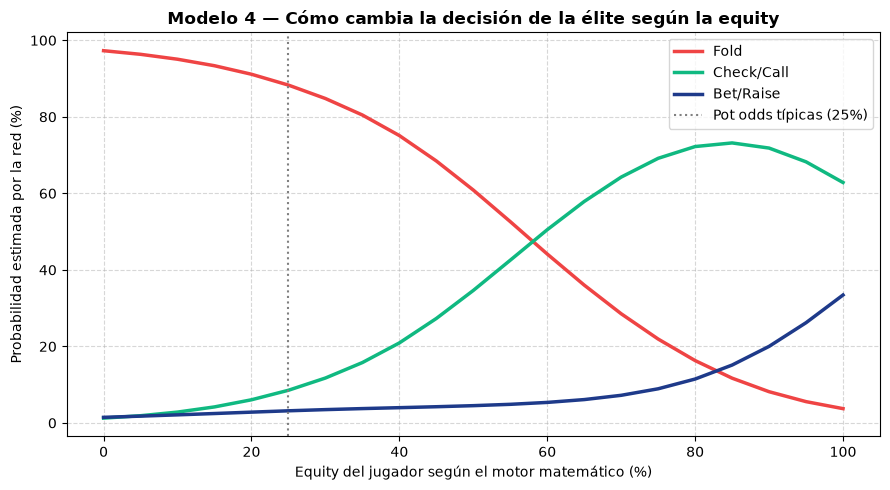

📊 Decisiones analizadas: 1,477 (postflop, enfrentando una apuesta)
 • Equity     0% ➔ Fold  97.3% | Call   1.3% | Raise   1.5%
 • Equity    25% ➔ Fold  88.3% | Call   8.5% | Raise   3.2%
 • Equity    50% ➔ Fold  60.9% | Call  34.6% | Raise   4.5%
 • Equity    75% ➔ Fold  21.9% | Call  69.2% | Raise   8.9%
 • Equity   100% ➔ Fold   3.7% | Call  62.8% | Raise  33.4%


In [11]:
# EXPERIMENTO 3 — SENSIBILIDAD A LA EQUITY (une la red con el motor matemático)
# Se toman las decisiones postflop de Test en las que el jugador enfrenta una apuesta y se
# cambia SOLO su equity, dejando todo lo demás igual (dependencia parcial).
subconjunto = df_test[(df_test['calle'] > 0) & (df_test['to_call'] > 0)].copy()
pot_odds_tipicas = subconjunto['pot_odds'].median()
valores_equity = np.linspace(0, 1, 21)
curvas = []
for v in valores_equity:
    modificado = subconjunto.copy()
    modificado['c_equity'] = v
    curvas.append(modelo.predict(scaler.transform(preparar(modificado, FEATURES)), verbose=0).mean(axis=0))
curvas = np.array(curvas)

plt.figure(figsize=(9, 5))
for k, (etiqueta, color) in enumerate([('Fold', '#ef4444'), ('Check/Call', '#10b981'), ('Bet/Raise', '#1e3a8a')]):
    plt.plot(valores_equity * 100, curvas[:, k] * 100, label=etiqueta, color=color, linewidth=2.5)
plt.axvline(pot_odds_tipicas * 100, color='gray', linestyle=':', label=f'Pot odds típicas ({pot_odds_tipicas * 100:.0f}%)')
plt.xlabel('Equity del jugador según el motor matemático (%)')
plt.ylabel('Probabilidad estimada por la red (%)')
plt.title('Modelo 4 — Cómo cambia la decisión de la élite según la equity', fontsize=12, fontweight='bold')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('../informe/figuras/modelo4_sensibilidad_equity.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"📊 Decisiones analizadas: {len(subconjunto):,} (postflop, enfrentando una apuesta)")
for v, fila in zip(valores_equity[::5], curvas[::5]):
    print(f" • Equity {v * 100:>5.0f}% ➔ Fold {fila[0] * 100:5.1f}% | Call {fila[1] * 100:5.1f}% | Raise {fila[2] * 100:5.1f}%")

📐 CALIBRACIÓN: cuando la red dice X% de confianza, ¿acierta el X%?
             decisiones  confianza_media  exactitud_real
tramo                                                   
(0.33, 0.5]         313            0.445           0.444
(0.5, 0.6]         1516            0.550           0.551
(0.6, 0.7]         1403            0.649           0.653
(0.7, 0.8]         1373            0.751           0.741
(0.8, 0.9]         1612            0.852           0.850
(0.9, 1.0]        10382            0.987           0.985


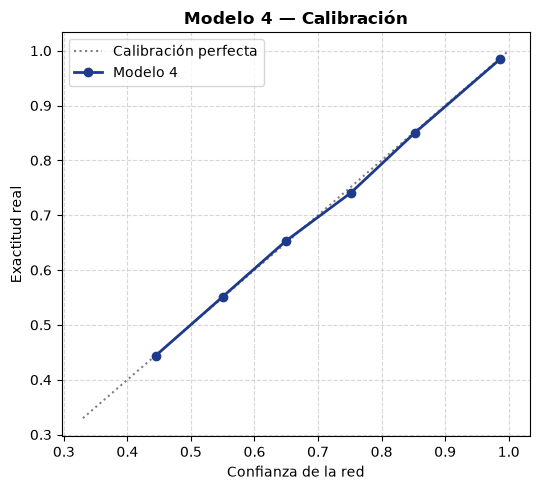

In [12]:
# Calibración de las probabilidades
analisis = pd.DataFrame({'acierto': y_pred == y_test, 'confianza': prob_test.max(axis=1)})
analisis['tramo'] = pd.cut(analisis['confianza'], [0.33, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
calibracion = analisis.groupby('tramo', observed=True).agg(
    decisiones=('acierto', 'size'), confianza_media=('confianza', 'mean'), exactitud_real=('acierto', 'mean'))
print("📐 CALIBRACIÓN: cuando la red dice X% de confianza, ¿acierta el X%?")
print(calibracion.round(3).to_string())

plt.figure(figsize=(5.5, 5))
plt.plot([0.33, 1], [0.33, 1], linestyle=':', color='gray', label='Calibración perfecta')
plt.plot(calibracion['confianza_media'], calibracion['exactitud_real'], marker='o', color='#1e3a8a', linewidth=2, label='Modelo 4')
plt.xlabel('Confianza de la red'); plt.ylabel('Exactitud real'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.title('Modelo 4 — Calibración', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo4_calibracion.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
import joblib

models_dir = "../models/v4_pluribus"
os.makedirs(models_dir, exist_ok=True)
model_file = os.path.join(models_dir, "pht_t_modelo4.keras")
scaler_file = os.path.join(models_dir, "scaler_modelo4.pkl")
features_file = os.path.join(models_dir, "variables_modelo4.json")

print("💾 Guardando el Modelo 4 en models/v4_pluribus/...")
modelo.save(model_file)
joblib.dump(scaler, scaler_file)
with open(features_file, 'w', encoding='utf-8') as f:
    json.dump({'features': FEATURES, 'variables_log': VARIABLES_LOG,
               'formato': 'No-Limit Hold\'em, 6 jugadores, 100 ciegas grandes (ciegas 50/100)'}, f, ensure_ascii=False, indent=2)
print("\n✅ ¡ARTEFACTOS GUARDADOS CON ÉXITO!")
print(f" • Red Neuronal: {model_file} ➔ ({os.path.getsize(model_file) / 1024:.1f} KB)")
print(f" • Escalador:    {scaler_file} ➔ ({os.path.getsize(scaler_file) / 1024:.1f} KB)")
print(f" • Variables:    {features_file}")

# Prueba de cordura con una decisión real de Test
modelo_cargado = keras.models.load_model(model_file)
scaler_cargado = joblib.load(scaler_file)
ejemplo = df_test[(df_test['calle'] == 1) & (df_test['to_call'] > 0)].iloc[[0]]
prob = modelo_cargado.predict(scaler_cargado.transform(preparar(ejemplo, FEATURES)), verbose=0)[0]
print(f"\n🧪 Decisión real de Test: {ejemplo['jugador'].iloc[0]} con {ejemplo['cartas'].iloc[0]} en {ejemplo['mesa'].iloc[0]} "
      f"(equity {ejemplo['c_equity'].iloc[0] * 100:.0f}%, pot odds {ejemplo['pot_odds'].iloc[0] * 100:.0f}%)")
print(f" • Red: Fold {prob[0] * 100:.1f}% | Call {prob[1] * 100:.1f}% | Raise {prob[2] * 100:.1f}% ➔ Jugada real: {nombres_clases[ejemplo['accion'].iloc[0]]}")

💾 Guardando el Modelo 4 en models/v4_pluribus/...

✅ ¡ARTEFACTOS GUARDADOS CON ÉXITO!
 • Red Neuronal: ../models/v4_pluribus\pht_t_modelo4.keras ➔ (688.8 KB)
 • Escalador:    ../models/v4_pluribus\scaler_modelo4.pkl ➔ (1.7 KB)
 • Variables:    ../models/v4_pluribus\variables_modelo4.json



🧪 Decisión real de Test: MrBlue con As2d en Kd2s5h (equity 61%, pot odds 20%)
 • Red: Fold 5.7% | Call 89.2% | Raise 5.1% ➔ Jugada real: Check/Call (1)


In [14]:
tabla = pd.DataFrame(resultados).T
for col in ['accuracy', 'acc_profesionales', 'acc_pluribus']:
    tabla[col] = (tabla[col] * 100).map(lambda v: f"{v:.2f}%")
print("=" * 110)
print("  TABLA COMPARATIVA FINAL — MODELO 4 (Test por sesiones)")
print("=" * 110)
print(tabla.to_string())
print("=" * 110)
print("📚 Referencia publicada (Havoc, AAMAS 2026, mismo dataset): 80.27% – 86.77% por jugador (Tabla 1)")

metricas_m4 = {
    "modelo": "Modelo 4 - MLP cartas + contexto, manos de Pluribus (6-max, 100bb), partición por sesión",
    "n_train": int(len(y_train)), "n_val": int(len(y_val)), "n_test": int(len(y_test)),
    "resultados": resultados,
    "reporte_por_clase": reporte_clases_m4,
    "matriz_confusion": cm.tolist(),
    "por_calle": por_calle,
    "validacion_cruzada": cv.to_dict(orient='records'),
    "validacion_cruzada_resumen": {c: {'media': float(cv[c].mean()), 'desv': float(cv[c].std())} for c in cv.columns if c not in ('ronda', 'decisiones')},
    "sensibilidad_equity": {'equity': valores_equity.tolist(), 'prob_fold_call_raise': curvas.tolist(), 'pot_odds_mediana': float(pot_odds_tipicas)},
    "calibracion": calibracion.reset_index().astype({'tramo': str}).to_dict(orient='records'),
    "epocas": len(history.history['loss']),
    "referencia_havoc": {"fuente": "Shapira et al., AAMAS 2026, Tabla 1", "rango_por_jugador": [0.8027, 0.8677]},
}
with open('../informe/metricas/modelo4.json', 'w', encoding='utf-8') as f:
    json.dump(metricas_m4, f, ensure_ascii=False, indent=2, default=float)
print("\n💾 Métricas guardadas en informe/metricas/modelo4.json")
print("🎉 ¡Modelo 4 completado!")

  TABLA COMPARATIVA FINAL — MODELO 4 (Test por sesiones)
                                                  accuracy acc_profesionales acc_pluribus  f1_macro  log_loss
Baseline 1: Clase Mayoritaria (Fold)                53.80%            53.99%       52.92%    0.2332    7.4458
Baseline 2: Árbol Prof. 3 (5 variables)             69.25%            69.67%       67.21%    0.4848    0.6787
Referencia: Gradient Boosting (47 variables)        87.20%            87.50%       85.70%    0.8358    0.2848
🎯 Red Neuronal MLP — Modelo 4 (cartas + contexto)   87.39%            87.66%       86.06%    0.8390    0.2787
Ablación: Sin cartas (solo contexto público)        70.78%            71.31%       68.14%    0.5831    0.6188
Ablación: Cartas sin equity del motor               87.19%            87.50%       85.70%    0.8368    0.2851
Ablación: Completo (cartas + equity del motor)      87.39%            87.66%       86.06%    0.8390    0.2787
📚 Referencia publicada (Havoc, AAMAS 2026, mismo dataset): 80.2

### 🧠 Análisis Crítico del Modelo 4

1. **De ~74% a ~87%:** con las cartas privadas visibles la red alcanza **87.39%** en test (F1-Macro 0.839). La validación cruzada por sesiones da **87.50% ± 0.25**, así que el resultado es estable y no depende de qué sesiones cayeron en el test.
2. **La ablación confirma la hipótesis del Modelo 3:** la misma red sin las variables de cartas obtiene 70.78%, prácticamente el mismo techo que en HandHQ (~74%) con datos de otros jugadores. Las cartas aportan **+16.4 puntos**; la equity del motor aporta solo +0.2 adicionales, porque la red ya deduce la fuerza de la mano a partir de las cartas. Su valor está en la interpretación y en unir la red con el motor matemático.
3. **El river con pocas manos sí es estable:** el miedo inicial era que ~1,000 decisiones de river por conjunto dieran métricas erráticas. En validación cruzada el river queda en 77.37% ± 1.55: más variable que el preflop (91.69% ± 0.26), pero dentro de un rango estrecho.
4. **Pluribus es un poco menos predecible que los profesionales:** 86.06% contra 87.66%. Pluribus mezcla acciones a propósito (estrategia aleatorizada), lo que lo hace más difícil de anticipar.
5. **Comparación con la literatura:** Havoc (Shapira et al., AAMAS 2026), una LSTM que también usa probabilidad de ganar en lugar de cartas crudas, reporta entre 80.27% y 86.77% por jugador. El Modelo 4 está en ese rango con un MLP más simple. Los datos y la configuración no son idénticos, así que la comparación es orientativa. El orden de dificultad coincide: *Fold* es la clase más fácil (F1 0.951) y *Bet/Raise* la más difícil (F1 0.773).
6. **Lo que enseña la curva de sensibilidad:** en 1,477 decisiones postflop frente a una apuesta (pot odds típicas de 25%), al subir la equity de 0% a 100% el *Fold* cae de 97.3% a 3.7% y la subida aparece al final (33.4%). Con 50% de equity la élite todavía se retira 60.9% de las veces: el motor calcula la equity contra manos aleatorias, pero quien apuesta no tiene una mano aleatoria. Los profesionales descuentan eso y la red lo aprendió.
7. **Probabilidades calibradas:** la confianza media coincide con la exactitud real en todos los tramos.
8. **Limitaciones:** son 10,000 manos de 14 jugadores (13 profesionales que se turnaron en las mesas, más Pluribus) en un único formato (mesas de 6, 100 ciegas grandes). El modelo describe **lo que harían estos jugadores de élite**, no la jugada matemáticamente óptima. La búsqueda de otras fuentes con cartas visibles de jugadores de élite no encontró conjuntos públicos utilizables.